In [1]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.ticker import MaxNLocator
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.collections import LineCollection
import pandas as pd
import glob
from shapely.geometry import Point,MultiPoint,Polygon
import pandas as pd
import netCDF4 as nc
from netCDF4 import Dataset, date2num
import datetime
import matplotlib
import argparse
import os, glob,sys
import time
import shutil
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import sys, pprint
sys.displayhook = pprint.pprint  # Improves print of variables (e.g. locals(), globals(), dir())) to screen
import shlex,subprocess
import numpy.matlib
from configparser import ConfigParser
sys.path.append("/home/pgouvenou/validation_tools_drifters/src/")
from Drift_Tools import ReturnUVlist, CalcCurlGlobC, CalcRelVorticity, ExtractSurface, match_elements, StringRegion, DispDirAndLength,  SeparationDistance, TrajDistBetweenTimesteps, SepDistanceEachTimestep, LiuScore, shift360, DriftersInZoneInPeriod, coord2index
from Drift_exec import run_parcels_Drift
import os, glob,sys
from operator import attrgetter
import matplotlib.ticker as mticker
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import cmocean
from matplotlib.ticker import MaxNLocator
from matplotlib.colors import BoundaryNorm
from matplotlib.gridspec import GridSpec
import getpass
username=getpass.getuser()
print('username: ',username)



username:  pgouvenou
username:  pgouvenou
None


In [2]:


config_object = ConfigParser()
config_object.read("config.ini")
config_info = config_object['CONFIG_BASE']
MODELS = config_info["MODELS"].split(',')
lon_min = int(config_info["lon_min"])
lon_max = int(config_info["lon_max"])
lat_min = int(config_info["lat_min"])
lat_max = int(config_info["lat_max"])
DATE1 = config_info["DATE_start"]
DATE2 = config_info["DATE_start"]
PROJECT = config_info["PROJECT"]
EXP_NAME = config_info["EXP_NAME"]
username = config_info["username"]
dir_work = config_info["dir_work"]
dir_in = config_info["dir_in"]
DRIFT_TIME = int(config_info["DRIFT_TIME"])
cloud_stat = config_info["cloud_stat"]
remote = config_info["remote"]
K_smag = config_info["K_smag"]
print("MODELS : ",MODELS)
print("Region : ",lon_min,", ",lon_max,", ",lat_min,", ",lat_max)
print("From : ",DATE1," to ",DATE2)

str_region = StringRegion(lon_min,lon_max,lat_min,lat_max)

#reconstruct date_start
DD1=int(DATE1[:2])
MM1=int(DATE1[2:4])
YYYY1=int(DATE1[4:])
print(DD1,'-',MM1,'-',YYYY1)
date_start = datetime.date(YYYY1, MM1, DD1)
str_date1=date_start.strftime('%Y-%m-%d')
date_start_min1 = date_start-datetime.timedelta(days=1)

#reconstruct date_end
DD2=int(DATE2[:2])
MM2=int(DATE2[2:4])
YYYY2=int(DATE2[4:])
date_end = datetime.date(YYYY2, MM2, DD2)
str_date2=date_end.strftime('%Y-%m-%d')
date_end_plus1 = date_end+datetime.timedelta(days=1)
date_end_plus_DRIFT_TIME = date_end+datetime.timedelta(days=DRIFT_TIME+1)
str_date_end_plus_DRIFT_TIME=date_end_plus_DRIFT_TIME.strftime('%Y-%m-%d')




T_DRIFT=(date_end-date_start).days
dir_out=dir_work+'/DRIFT/'+PROJECT+'/'+EXP_NAME+'/ZONE_'+str_region+'/'


MODELS :  ['IBI36']
Region :  -19 ,  5 ,  26 ,  56
From :  01012019  to  01012019
1 - 1 - 2019


In [3]:
str_date1

'2019-01-01'

In [4]:
zlevel = 11
config_object = ConfigParser()
config_object.read(dir_in+"src/config_products.ini")
path_UV = []
fname_prefix = []
var_u_mod = []
var_v_mod = []
meshmask = []
dir_work_mod = []
u_files_mod = []
v_files_mod = []
colors = []
eddy_track = []
for MODEL in MODELS:
    if MODEL not in config_object.sections():
        print(MODEL, "is either a typo or not yet tuned for this program")
        print('model runs available: ',config_object.sections())
        sys.exit(1)
    run_info = config_object[MODEL]
    path_UV.append(run_info["path"])
    fname_prefix.append(run_info["fname_prefix"])
    var_u_mod.append(run_info["var_u"])
    var_v_mod.append(run_info["var_v"])
    meshmask.append(run_info["meshmask"])
    colors.append(run_info["color"])
    eddy_track.append(run_info["eddy_track"])
    dir_work_mod.append(dir_out+'/EXP/'+MODEL+'/')
    if not os.path.exists(dir_work_mod[-1]):
        print('\ncreate folder : ', dir_work_mod[-1])
        # Create directory where to store results:
        os.makedirs(dir_work_mod[-1])

    if MODEL in ['PSY4V3R1','IBI36','GLO12V4']:
        u_files_mod_3D, v_files_mod_3D = ReturnUVlist(MODEL, date_start_min1, date_end_plus_DRIFT_TIME)
        u_files, v_files = ExtractSurface(MODEL,u_files_mod_3D, v_files_mod_3D,zlevel,var_u_mod, var_v_mod, dir_work+'MODEL_OUTPUT/'+MODEL+'/UV/15m/')
        u_files_mod.append(u_files)
        v_files_mod.append(v_files)
    else : 
        u_files, v_files = ReturnUVlist(MODEL, date_start_min1, date_end_plus_DRIFT_TIME)
        u_files_mod.append(u_files)
        v_files_mod.append(v_files)





#-----------------------------------------------------------------------------------------
#                      READ IN FIELDSET
#-----------------------------------------------------------------------------------------
script ReturnUVlist
model : IBI36
date_start : 2018-12-31
date_end : 2019-01-22
dir_in : None
path_UV:  /data/rd_exchange/pgouvenou/DATA/IBI/
fname_prefix:  IBI36V5_1dAV_
identify U,V :
years= range(2018, 2020)
2018
/data/rd_exchange/pgouvenou/DATA/IBI/IBI36V5_1dAV_*gridU_R*.nc
2019
/data/rd_exchange/pgouvenou/DATA/IBI/IBI36V5_1dAV_*gridU_R*.nc
f_input_start IBI36V5_1dAV_20181231
f_input_end IBI36V5_1dAV_20190122
UV field, identify start date:
nb files in Ulist =  252
     IBI36V5_1dAV_20181231  in line  5  : /data/rd_exchange/pgouvenou/DATA/IBI/IBI36V5_1dAV_20181231_20190101_gridU_R20190102.nc
     IBI36V5_1dAV_20181231  in line  131  : /data/rd_exchange/pgouvenou/DATA/IBI/IBI36V5_1dAV_20181231_20190101_gridU_R20190102.nc
UV field, identify end date
     IBI36V5_1dAV

In [5]:
# retrieve eddy track in the good area and time period
nb_pts = 50
res_pts = 0.05#°

xs_cyclonic = []
ys_cyclonic = []
xs_anticyclonic = []
ys_anticyclonic = []
eddy_cyclonic = []
eddy_anticyclonic = []
pts_in_eddy_cyclonic = []
pts_in_eddy_anticyclonic = []
for i in range(len(MODELS)):

    data_eddy_cyclonic = xr.open_dataset(eddy_track[i]+'Cyclonic.nc')
    data_eddy_anticyclonic = xr.open_dataset(eddy_track[i]+'Anticyclonic.nc')
    longitude_eddy_cyclonic = data_eddy_cyclonic.effective_contour_longitude.values[np.where(data_eddy_cyclonic.time.values == np.datetime64(str_date1))]
    latitude_eddy_cyclonic = data_eddy_cyclonic.effective_contour_latitude.values[np.where(data_eddy_cyclonic.time.values == np.datetime64(str_date1))]
    longitude_eddy_anticyclonic = data_eddy_anticyclonic.effective_contour_longitude.values[np.where(data_eddy_anticyclonic.time.values == np.datetime64(str_date1))]
    latitude_eddy_anticyclonic = data_eddy_anticyclonic.effective_contour_latitude.values[np.where(data_eddy_anticyclonic.time.values == np.datetime64(str_date1))]
    time_eddy_cyclonic = data_eddy_cyclonic.time.values[np.where(data_eddy_cyclonic.time.values == np.datetime64(str_date1))]
    time_eddy_anticyclonic = data_eddy_anticyclonic.time.values[np.where(data_eddy_anticyclonic.time.values == np.datetime64(str_date1))]
    max_lat_cyclonic = np.max(latitude_eddy_cyclonic,axis = 1)
    min_lat_cyclonic = np.min(latitude_eddy_cyclonic,axis = 1)
    max_lon_cyclonic = np.max(longitude_eddy_cyclonic,axis = 1)
    min_lon_cyclonic = np.min(longitude_eddy_cyclonic,axis = 1)
    
    max_lat_anticyclonic = np.max(latitude_eddy_anticyclonic,axis = 1)
    min_lat_anticyclonic = np.min(latitude_eddy_anticyclonic,axis = 1)
    max_lon_anticyclonic = np.max(longitude_eddy_anticyclonic,axis = 1)
    min_lon_anticyclonic = np.min(longitude_eddy_anticyclonic,axis = 1)    
    
    ind_zone_cyclonic = np.where((max_lat_cyclonic<lat_max)*(min_lat_cyclonic>lat_min)*(min_lon_cyclonic>lon_min)*(max_lon_cyclonic<lon_max))
    ind_zone_anticyclonic = np.where((max_lat_anticyclonic<lat_max)*(min_lat_anticyclonic>lat_min)*(min_lon_anticyclonic>lon_min)*(max_lon_anticyclonic<lon_max))
    
    longitude_eddy_cyclonic  = longitude_eddy_cyclonic[ind_zone_cyclonic] 
    latitude_eddy_cyclonic = latitude_eddy_cyclonic[ind_zone_cyclonic]
    longitude_eddy_anticyclonic  = longitude_eddy_anticyclonic[ind_zone_anticyclonic] 
    latitude_eddy_anticyclonic = latitude_eddy_anticyclonic[ind_zone_anticyclonic]
    time_eddy_cyclonic = time_eddy_cyclonic[ind_zone_cyclonic]
    time_eddy_anticyclonic = time_eddy_anticyclonic[ind_zone_anticyclonic]
    coords_T0_cyclonic = np.array([np.concatenate((longitude_eddy_cyclonic[j].reshape((nb_pts,1)),
                latitude_eddy_cyclonic[j].reshape((nb_pts,1))),axis = 1) for j in range(latitude_eddy_cyclonic.shape[0]) ])
    coords_T0_anticyclonic = np.array([np.concatenate((longitude_eddy_anticyclonic[j].reshape((nb_pts,1)),
                latitude_eddy_anticyclonic[j].reshape((nb_pts,1))),axis = 1) for j in range(latitude_eddy_anticyclonic.shape[0]) ])
    polygon_cyclonic = np.array([Polygon(coords_T0_cyclonic[j]) for j in range (latitude_eddy_cyclonic.shape[0])])
    polygon_anticyclonic = np.array([Polygon(coords_T0_anticyclonic[j]) for j in range (latitude_eddy_anticyclonic.shape[0])])
    eddy_cyclonic.append(polygon_cyclonic)
    eddy_anticyclonic.append(polygon_anticyclonic)
    bounds_cyclonic = np.array([polygon_cyclonic[j].bounds for j in range(latitude_eddy_cyclonic.shape[0])])
    bounds_anticyclonic = np.array([polygon_anticyclonic[j].bounds for j in range(latitude_eddy_anticyclonic.shape[0])])

    print(bounds_anticyclonic.shape)
    print(bounds_cyclonic.shape)
    
    pts_inside_cyclonic = []
    for k in range (bounds_cyclonic.shape[0]):
        pts_cyclonic_int = []
        for lon_cyclonic in np.arange(bounds_cyclonic[k][0],bounds_cyclonic[k][2],res_pts):
            for lat_cyclonic in np.arange(bounds_cyclonic[k][1],bounds_cyclonic[k][3],res_pts):
                pts_cyclonic_int.append((lon_cyclonic,lat_cyclonic))
        multi_pts = MultiPoint(pts_cyclonic_int)       
        pts_inside_cyclonic_int = []
        for pts in multi_pts:
            if polygon_cyclonic[k].contains(pts):
                pts_inside_cyclonic_int.append(pts)
        pts_inside_cyclonic.append(MultiPoint(pts_inside_cyclonic_int))
    pts_in_eddy_cyclonic.append(pts_inside_cyclonic)
    pts_inside_anticyclonic = []
    for k in range (bounds_anticyclonic.shape[0]):
        pts_anticyclonic_int = []
        for lon_anticyclonic in np.arange(bounds_anticyclonic[k][0],bounds_anticyclonic[k][2],res_pts):
            for lat_anticyclonic in np.arange(bounds_anticyclonic[k][1],bounds_anticyclonic[k][3],res_pts):
                pts_anticyclonic_int.append((lon_anticyclonic,lat_anticyclonic))
        multi_pts = MultiPoint(pts_anticyclonic_int)       
        pts_inside_anticyclonic_int = []
        for pts in multi_pts:
            if polygon_anticyclonic[k].contains(pts):
                pts_inside_anticyclonic_int.append(pts)
        pts_inside_anticyclonic.append(MultiPoint(pts_inside_anticyclonic_int))
    pts_in_eddy_anticyclonic.append(pts_inside_anticyclonic)
    xs_cyclonic.append([b.x for a in pts_inside_cyclonic for b in a])
    ys_cyclonic.append([b.y for a in pts_inside_cyclonic for b in a])
    xs_anticyclonic.append([b.x for a in pts_inside_anticyclonic for b in a])
    ys_anticyclonic.append([b.y for a in pts_inside_anticyclonic for b in a])

(82, 4)
(130, 4)


/tmp/ipykernel_6650/3210127717.py:64: ShapelyDeprecationWarning: Iteration over multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  for pts in multi_pts:
/tmp/ipykernel_6650/3210127717.py:77: ShapelyDeprecationWarning: Iteration over multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  for pts in multi_pts:
/tmp/ipykernel_6650/3210127717.py:82: ShapelyDeprecationWarning: Iteration over multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  xs_cyclonic.append([b.x for a in pts_inside_cyclonic for b in a])
/tmp/ipykernel_6650/3210127717.py:83: ShapelyDeprecationWarning: Iteration over multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to

In [8]:
parcels_files = []
for i in range(len(MODELS)):
    f_traj_cyclonic = dir_work_mod[i]+ "Trajectories_"+MODELS[i]+'_'+str_date1+'_'+str(DRIFT_TIME)+'_at_EDDYloc_cyclonic.zarr'
    f_traj_anticyclonic = dir_work_mod[i]+ "Trajectories_"+MODELS[i]+'_'+str_date1+'_'+str(DRIFT_TIME)+'_at_EDDYloc_anticyclonic.zarr'
    parcels_files.append([f_traj_cyclonic,f_traj_anticyclonic])
    id_pts = np.arange(1,len(xs_cyclonic[i])+1,1)
    run_parcels_Drift(MODELS[i], u_files_mod[i], var_u_mod[i], v_files_mod[i], var_v_mod[i], meshmask[i],\
                                 np.array(xs_cyclonic[i]), np.array(ys_cyclonic[i]),id_pts, DRIFT_TIME,\
                                 f_traj_cyclonic, radius_cloud=0, seeding_resolution=0, \
                                 time_period=False,hour = 12)

    id_pts = np.arange(1,len(xs_anticyclonic[i])+1,1)
    run_parcels_Drift(MODELS[i], u_files_mod[i], var_u_mod[i], v_files_mod[i], var_v_mod[i], meshmask[i],\
                                 np.array(xs_anticyclonic[i]), np.array(ys_anticyclonic[i]),id_pts, DRIFT_TIME,\
                                 f_traj_anticyclonic, radius_cloud=0, seeding_resolution=0, \
                                 time_period=False,hour = 12)
    

#-----------------------------------------------------------------------------------------
#      START RUN_PARCEL_DRIFT: 1. FIELDSET1                 
#-----------------------------------------------------------------------------------------
filenames[U][data] ['/data/rd_exchange/pgouvenou/MODEL_OUTPUT/IBI36/UV/15m//2018/IBI36V5_1dAV_20181231_20190101_gridU_R20190102.nc', '/data/rd_exchange/pgouvenou/MODEL_OUTPUT/IBI36/UV/15m//2019/IBI36V5_1dAV_20190101_20190102_gridU_R20190102.nc', '/data/rd_exchange/pgouvenou/MODEL_OUTPUT/IBI36/UV/15m//2019/IBI36V5_1dAV_20190102_20190103_gridU_R20190109.nc', '/data/rd_exchange/pgouvenou/MODEL_OUTPUT/IBI36/UV/15m//2019/IBI36V5_1dAV_20190103_20190104_gridU_R20190109.nc', '/data/rd_exchange/pgouvenou/MODEL_OUTPUT/IBI36/UV/15m//2019/IBI36V5_1dAV_20190104_20190105_gridU_R20190109.nc', '/data/rd_exchange/pgouvenou/MODEL_OUTPUT/IBI36/UV/15m//2019/IBI36V5_1dAV_20190105_20190106_gridU_R20190109.nc', '/data/rd_exchange/pgouvenou/MODEL_OUTPUT/IBI36/UV/15m//201

INFO: Compiled ArraySampleParticleAdvectionRK4periodicBCAge ==> /tmp/parcels-2170/libf1bf9bf3ba9e500275ae4d904a3f81c2_0.so
INFO:parcels.tools.loggers:Compiled ArraySampleParticleAdvectionRK4periodicBCAge ==> /tmp/parcels-2170/libf1bf9bf3ba9e500275ae4d904a3f81c2_0.so
INFO: Output files are stored in /data/rd_exchange/pgouvenou//DRIFT/test_ibi/ibi_area/ZONE_19W5E-26N56N//EXP/IBI36/Trajectories_IBI36_2019-01-01_20_at_EDDYloc_cyclonic.zarr.
INFO:parcels.tools.loggers:Output files are stored in /data/rd_exchange/pgouvenou//DRIFT/test_ibi/ibi_area/ZONE_19W5E-26N56N//EXP/IBI36/Trajectories_IBI36_2019-01-01_20_at_EDDYloc_cyclonic.zarr.
100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1728000.0/1728000.0 [00:36<00:00, 47809.98it/s]


Check output: /data/rd_exchange/pgouvenou//DRIFT/test_ibi/ibi_area/ZONE_19W5E-26N56N//EXP/IBI36/Trajectories_IBI36_2019-01-01_20_at_EDDYloc_cyclonic.zarr
 EXP1 FINISHED -----   06/15/2023, 10:47:19
#-----------------------------------------------------------------------------------------
#      START RUN_PARCEL_DRIFT: 1. FIELDSET1                 
#-----------------------------------------------------------------------------------------
filenames[U][data] ['/data/rd_exchange/pgouvenou/MODEL_OUTPUT/IBI36/UV/15m//2018/IBI36V5_1dAV_20181231_20190101_gridU_R20190102.nc', '/data/rd_exchange/pgouvenou/MODEL_OUTPUT/IBI36/UV/15m//2019/IBI36V5_1dAV_20190101_20190102_gridU_R20190102.nc', '/data/rd_exchange/pgouvenou/MODEL_OUTPUT/IBI36/UV/15m//2019/IBI36V5_1dAV_20190102_20190103_gridU_R20190109.nc', '/data/rd_exchange/pgouvenou/MODEL_OUTPUT/IBI36/UV/15m//2019/IBI36V5_1dAV_20190103_20190104_gridU_R20190109.nc', '/data/rd_exchange/pgouvenou/MODEL_OUTPUT/IBI36/UV/15m//2019/IBI36V5_1dAV_20190104_2019

INFO: Compiled ArraySampleParticleAdvectionRK4periodicBCAge ==> /tmp/parcels-2170/lib7f3d57dbaeb3224c6674fef587bf785a_0.so
INFO:parcels.tools.loggers:Compiled ArraySampleParticleAdvectionRK4periodicBCAge ==> /tmp/parcels-2170/lib7f3d57dbaeb3224c6674fef587bf785a_0.so
INFO: Output files are stored in /data/rd_exchange/pgouvenou//DRIFT/test_ibi/ibi_area/ZONE_19W5E-26N56N//EXP/IBI36/Trajectories_IBI36_2019-01-01_20_at_EDDYloc_anticyclonic.zarr.
INFO:parcels.tools.loggers:Output files are stored in /data/rd_exchange/pgouvenou//DRIFT/test_ibi/ibi_area/ZONE_19W5E-26N56N//EXP/IBI36/Trajectories_IBI36_2019-01-01_20_at_EDDYloc_anticyclonic.zarr.
100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1728000.0/1728000.0 [00:33<00:00, 52258.64it/s]

Check output: /data/rd_exchange/pgouvenou//DRIFT/test_ibi/ibi_area/ZONE_19W5E-26N56N//EXP/IBI36/Trajectories_IBI36_2019-01-01_20_at_EDDYloc_anticyclonic.zarr
 EXP1 FINISHED -----   06/15/2023, 10:48:06


In [ ]:
# STATS on Trajectories

/home/pgouvenou/miniconda3/envs/env_py36_parcels_2022/lib/python3.10/site-packages/cartopy/mpl/gridliner.py:451: UserWarning: The .xlabels_top attribute is deprecated. Please use .top_labels to toggle visibility instead.
  warnings.warn('The .xlabels_top attribute is deprecated. Please '
/home/pgouvenou/miniconda3/envs/env_py36_parcels_2022/lib/python3.10/site-packages/cartopy/mpl/gridliner.py:487: UserWarning: The .ylabels_right attribute is deprecated. Please use .right_labels to toggle visibility instead.
  warnings.warn('The .ylabels_right attribute is deprecated. Please '


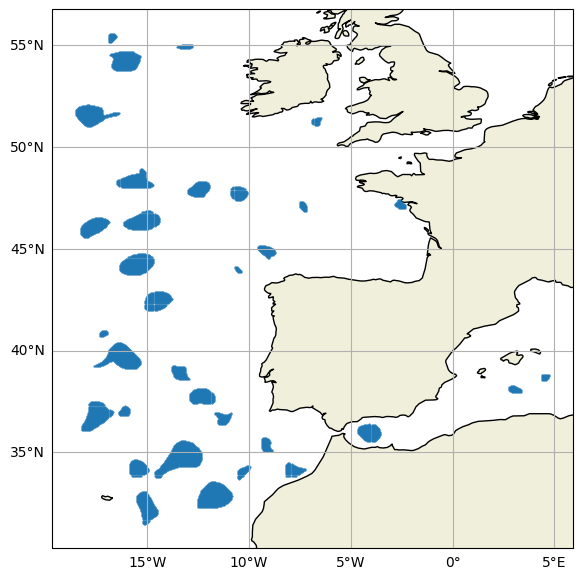

In [9]:
matplotlib.use('Agg')
%matplotlib inline
#data = xr.open_dataset(parcels_files[0][0])
fig  = plt.figure(figsize=(11,7))
axs = plt.axes(projection=ccrs.PlateCarree())
axs.coastlines(resolution='50m')
gl = axs.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)
gl.xlabels_top = False
gl.ylabels_right = False
axs.add_feature(cfeature.LAND)
axs.plot(xs_anticyclonic[0],ys_anticyclonic[0],'o',ms= 0.5)


In [36]:
for i in range(len(MODELS)):
    
    traj_cyclonic = xr.open_dataset(parcels_files[i][0])
    lon_cyclonic = traj_cyclonic.lon.values
    lat_cyclonic = traj_cyclonic.lat.values
    time_cyclonic = traj_cyclonic.time.values
    traj_anticyclonic = xr.open_dataset(parcels_files[i][1])
    lon_anticyclonic = traj_anticyclonic.lon.values
    lat_anticyclonic = traj_anticyclonic.lat.values
    time_anticyclonic = traj_anticyclonic.time.values
    # reconstruct
    lon_cyclonic_reshape = []
    lat_cyclonic_reshape = []
    time_cyclonic_reshape = []
    last = 0
    for nb_eddy in range (len(pts_in_eddy_cyclonic[i])):
        if nb_eddy ==0:
            lon_cyclonic_reshape.append(lon_cyclonic[0:len(pts_in_eddy_cyclonic[i][nb_eddy])])
            lat_cyclonic_reshape.append(lat_cyclonic[0:len(pts_in_eddy_cyclonic[i][nb_eddy])])
            time_cyclonic_reshape.append(time_cyclonic[0:len(pts_in_eddy_cyclonic[i][nb_eddy])])

        else:
            lon_cyclonic_reshape.append(lon_cyclonic[last:last+len(pts_in_eddy_cyclonic[i][nb_eddy])])
            lat_cyclonic_reshape.append(lat_cyclonic[last:last+len(pts_in_eddy_cyclonic[i][nb_eddy])])
            time_cyclonic_reshape.append(time_cyclonic[last:last+len(pts_in_eddy_cyclonic[i][nb_eddy])])
        last += len(pts_in_eddy_cyclonic[i][nb_eddy])
        
    lon_anticyclonic_reshape = []
    lat_anticyclonic_reshape = []
    time_anticyclonic_reshape = []
    last = 0
    for nb_eddy in range (len(pts_in_eddy_anticyclonic[i])):
        if nb_eddy ==0:
            lon_anticyclonic_reshape.append(lon_anticyclonic[0:len(pts_in_eddy_anticyclonic[i][nb_eddy])])
            lat_anticyclonic_reshape.append(lat_anticyclonic[0:len(pts_in_eddy_anticyclonic[i][nb_eddy])])
            time_anticyclonic_reshape.append(time_anticyclonic[0:len(pts_in_eddy_anticyclonic[i][nb_eddy])])

        else:
            lon_anticyclonic_reshape.append(lon_anticyclonic[last:last+len(pts_in_eddy_anticyclonic[i][nb_eddy])])
            lat_anticyclonic_reshape.append(lat_anticyclonic[last:last+len(pts_in_eddy_anticyclonic[i][nb_eddy])])
            time_anticyclonic_reshape.append(time_anticyclonic[last:last+len(pts_in_eddy_anticyclonic[i][nb_eddy])])
        last += len(pts_in_eddy_anticyclonic[i][nb_eddy])
        
    
    
    data_eddy_cyclonic = xr.open_dataset(eddy_track[i]+'Cyclonic.nc')
    data_eddy_anticyclonic = xr.open_dataset(eddy_track[i]+'Anticyclonic.nc')
    longitude_eddy_cyclonic = data_eddy_cyclonic.effective_contour_longitude.values[np.where((data_eddy_cyclonic.time.values < np.datetime64(str_date_end_plus_DRIFT_TIME))*(data_eddy_cyclonic.time.values >= np.datetime64(str_date1)))]
    latitude_eddy_cyclonic = data_eddy_cyclonic.effective_contour_latitude.values[np.where((data_eddy_cyclonic.time.values < np.datetime64(str_date_end_plus_DRIFT_TIME))*(data_eddy_cyclonic.time.values >= np.datetime64(str_date1)))]
    longitude_eddy_anticyclonic = data_eddy_anticyclonic.effective_contour_longitude.values[np.where((data_eddy_anticyclonic.time.values < np.datetime64(str_date_end_plus_DRIFT_TIME))*(data_eddy_anticyclonic.time.values >= np.datetime64(str_date1)))]
    latitude_eddy_anticyclonic = data_eddy_anticyclonic.effective_contour_latitude.values[np.where((data_eddy_anticyclonic.time.values < np.datetime64(str_date_end_plus_DRIFT_TIME))*(data_eddy_anticyclonic.time.values >= np.datetime64(str_date1)))]
    time_eddy_cyclonic = data_eddy_cyclonic.time.values[np.where((data_eddy_cyclonic.time.values < np.datetime64(str_date_end_plus_DRIFT_TIME))*(data_eddy_cyclonic.time.values >= np.datetime64(str_date1)))]
    time_eddy_anticyclonic = data_eddy_anticyclonic.time.values[np.where((data_eddy_anticyclonic.time.values < np.datetime64(str_date_end_plus_DRIFT_TIME))*(data_eddy_anticyclonic.time.values >= np.datetime64(str_date1)))]
    tps = np.arange(np.datetime64(str_date1),np.datetime64(str_date_end_plus_DRIFT_TIME))
    
    for j in range (time_anticyclonic_reshape[i].shape[1]):
        fig  = plt.figure(figsize=(11,7))
        ax = plt.axes(projection=ccrs.PlateCarree())
        ax.coastlines(resolution='50m')
        gl = ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)
        gl.xlabels_top = False
        gl.ylabels_right = False
        ax.add_feature(cfeature.LAND)
        for k in range (len(lon_anticyclonic_reshape)):
            ax.plot(lon_anticyclonic_reshape[k][:,j],lat_anticyclonic_reshape[k][:,j],'o',ms = 0.2,c = "b")
        ind_time = np.where(time_eddy_anticyclonic == tps[j//4])
        for lon,lat in zip(longitude_eddy_anticyclonic[ind_time],latitude_eddy_anticyclonic[ind_time]):
            ax.plot(lon,lat,c='r' )
        ax.set_xlim([lon_min,lon_max])
        ax.set_ylim([lat_min,lat_max])
        plt.savefig('/home/pgouvenou/drifter_comparison/ANALYSE/PLOT/IBI_EDDY_LAG/Anticyclonic_15m_20days_'+MODELS[i]+'_20190101_{:02}.png'.format(j))
        plt.close('all')
        
    for j in range (time_cyclonic_reshape[i].shape[1]):
        fig  = plt.figure(figsize=(11,7))
        ax = plt.axes(projection=ccrs.PlateCarree())
        ax.coastlines(resolution='50m')
        gl = ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)
        gl.xlabels_top = False
        gl.ylabels_right = False
        ax.add_feature(cfeature.LAND)
        for k in range (len(lon_cyclonic_reshape)):
            ax.plot(lon_cyclonic_reshape[k][:,j],lat_cyclonic_reshape[k][:,j],'o',ms = 0.2,c = "b")
        ind_time = np.where(time_eddy_cyclonic == tps[j//4])
        for lon,lat in zip(longitude_eddy_cyclonic[ind_time],latitude_eddy_cyclonic[ind_time]):
            ax.plot(lon,lat,c='r' )
        ax.set_xlim([lon_min,lon_max])
        ax.set_ylim([lat_min,lat_max])
        plt.savefig('/home/pgouvenou/drifter_comparison/ANALYSE/PLOT/IBI_EDDY_LAG/Cyclonic_15m_20days_'+MODELS[i]+'_20190101_{:02}.png'.format(j))
        plt.close('all')


/home/pgouvenou/miniconda3/envs/env_py36_parcels_2022/lib/python3.10/site-packages/xarray/backends/plugins.py:139: RuntimeWarning: 'netcdf4' fails while guessing
  warnings.warn(f"{engine!r} fails while guessing", RuntimeWarning)
/home/pgouvenou/miniconda3/envs/env_py36_parcels_2022/lib/python3.10/site-packages/xarray/backends/plugins.py:139: RuntimeWarning: 'scipy' fails while guessing
  warnings.warn(f"{engine!r} fails while guessing", RuntimeWarning)
/home/pgouvenou/miniconda3/envs/env_py36_parcels_2022/lib/python3.10/site-packages/xarray/backends/plugins.py:139: RuntimeWarning: 'netcdf4' fails while guessing
  warnings.warn(f"{engine!r} fails while guessing", RuntimeWarning)
/home/pgouvenou/miniconda3/envs/env_py36_parcels_2022/lib/python3.10/site-packages/xarray/backends/plugins.py:139: RuntimeWarning: 'scipy' fails while guessing
  warnings.warn(f"{engine!r} fails while guessing", RuntimeWarning)
/tmp/ipykernel_23765/2381687046.py:18: ShapelyDeprecationWarning: __len__ for multi-

/home/pgouvenou/miniconda3/envs/env_py36_parcels_2022/lib/python3.10/site-packages/cartopy/mpl/gridliner.py:451: UserWarning: The .xlabels_top attribute is deprecated. Please use .top_labels to toggle visibility instead.
  warnings.warn('The .xlabels_top attribute is deprecated. Please '
/home/pgouvenou/miniconda3/envs/env_py36_parcels_2022/lib/python3.10/site-packages/cartopy/mpl/gridliner.py:487: UserWarning: The .ylabels_right attribute is deprecated. Please use .right_labels to toggle visibility instead.
  warnings.warn('The .ylabels_right attribute is deprecated. Please '


In [35]:
len(pts_in_eddy_anticyclonic[i])

82

In [12]:
np.where(time_eddy_cyclonic==np.datetime64(str_date1))

(array([   0,   19,   40,   61,   71,   83,  104,  125,  146,  167,  188,
         209,  219,  240,  253,  274,  295,  316,  328,  349,  370,  383,
         404,  425,  446,  467,  488,  502,  523,  544,  562,  581,  602,
         612,  633,  643,  664,  683,  704,  725,  745,  766,  787,  802,
         823,  844,  865,  886,  899,  910,  931,  952,  973,  994, 1015,
        1036]),)

In [13]:
 np.arange(np.datetime64(str_date1),np.datetime64(str_date_end_plus_DRIFT_TIME))

array(['2019-01-01', '2019-01-02', '2019-01-03', '2019-01-04',
       '2019-01-05', '2019-01-06', '2019-01-07', '2019-01-08',
       '2019-01-09', '2019-01-10', '2019-01-11', '2019-01-12',
       '2019-01-13', '2019-01-14', '2019-01-15', '2019-01-16',
       '2019-01-17', '2019-01-18', '2019-01-19', '2019-01-20',
       '2019-01-21'], dtype='datetime64[D]')

In [17]:
lon_cyclonic_reshape[0].shape

(26, 81)

In [22]:
len(lon_cyclonic_reshape)

55